### Checkpoint 1

Implement your algorithm to process and annotate the traces of the 20 unipolar electrogram signals, identifying focal activity based on activation patterns and signal morphology.

The algorithm must return the following outputs:

1. **Activation Annotations**: for each of the 20 signals, generate a list of activation times. These activation times correspond to the local minima of the first derivative of the signal, indicating the moments of depolarization at each electrode.
2. **Focal proximity**: assign a score of 1 to the sensor closest to the focal activity and 0 to all others. If the focal activity is within two sensors (up to a specified tolerance), assign 0.5 to each of the two sensors.
This output should be guided by signal morphology: focal activity is expected to correspond to a QS morphology (i.e., a single dominant negative deflection).

Provide your algorithm's implementation in this notebook to annotate the traces of the 20 unipolar signals and identify focal activity based on activation patterns and waveform morphology.



In [22]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema

In [23]:
# load data
signals = np.load('checkpoint1dataset.npy')

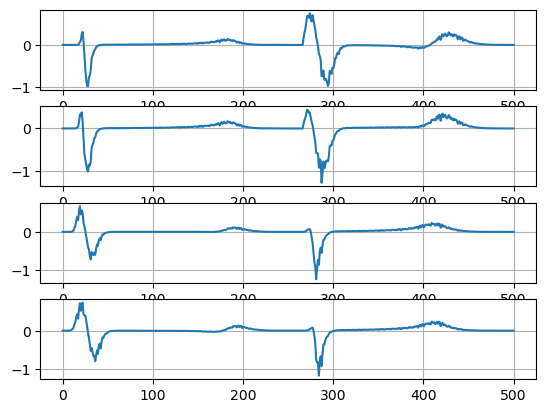

In [ ]:
# select event to be display
ind_event = 2

# select a spline (options: 0,1,2,3,4)
ind_spline = 2

# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

signals_event = signals[ind_event,:,:]

Shape originale: (5, 20, 501)
Preprocessing completato.


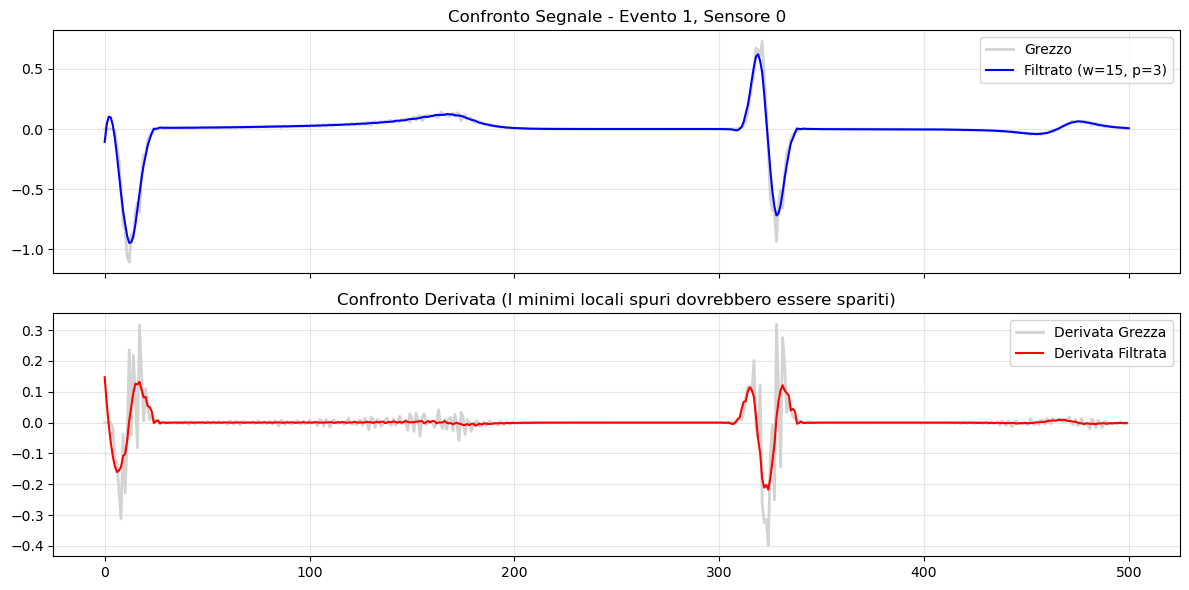

In [ ]:
#Applico un filtro di Savitzky-Golay per stabilizzare la derivata e ridurre i falsi minimi locali

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

print("Shape originale:", signals.shape)

# Creiamo un array vuoto con la stessa forma per i segnali filtrati
signals_filtered = np.zeros_like(signals)

# window_length: la lunghezza della finestra (deve essere dispari). 
# Più è grande, più il segnale viene lisciato. Troppo grande = perdi il picco.
window_length = 15 

# polyorder: l'ordine del polinomio usato per fittare la finestra. 
poly_order = 3 

# Applichiamo il filtro a tutto il dataset
for ev in range(signals.shape[0]):
    for sens in range(signals.shape[1]):
        signals_filtered[ev, sens, :] = savgol_filter(signals[ev, sens, :], window_length, poly_order)

print("Preprocessing completato.")

# Scegliamo un evento e un sensore a caso per vedere l'effetto
ev_test = 1
sens_test = 0

sig_raw = signals[ev_test, sens_test, :]
sig_filt = signals_filtered[ev_test, sens_test, :]

# Calcoliamo le derivate per vedere quanto abbiamo stabilizzato argrelextrema
diff_raw = np.diff(sig_raw)
diff_filt = np.diff(sig_filt)

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Plot Segnale
axs[0].plot(sig_raw, label='Grezzo', color='lightgray', linewidth=2)
axs[0].plot(sig_filt, label=f'Filtrato (w={window_length}, p={poly_order})', color='blue', linewidth=1.5)
axs[0].set_title(f'Confronto Segnale - Evento {ev_test}, Sensore {sens_test}')
axs[0].legend()
axs[0].grid(True, alpha=0.3)

# Plot Derivata 
axs[1].plot(diff_raw, label='Derivata Grezza', color='lightgray', linewidth=2)
axs[1].plot(diff_filt, label='Derivata Filtrata', color='red', linewidth=1.5)
axs[1].set_title('Confronto Derivata (I minimi locali spuri dovrebbero essere spariti)')
axs[1].legend()
axs[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

signals_event=signals_filtered[ind_event,:,:]

In [48]:
def GroupSolutionCP1(signals_event):
    n_sensors = signals_event.shape[0]
    timings = []
    
    min_dist = 100 
    time_tol = 4
    
    act_times = [[], []] 
    qs_flags = [[], []]

    #Soglia sulla derivata
    # Calcoliamo la derivata per tutti i sensori contemporaneamente
    ds_all = np.diff(signals_event, axis=1)
    
    # Troviamo la pendenza negativa massima assoluta in tutto l'evento.
    global_min_slope = np.min(ds_all)
    
    # Fissiamo la soglia al 30% di questa pendenza massima
    slope_threshold = 0.30 * global_min_slope

    for i in range(n_sensors):
        #Calcolo la derivata prima e identifico i minimi locali
        ds = np.diff(signals_event[i, :])
        all_min_indices = argrelextrema(ds, np.less)[0]

        # TApplichiamo il filtro e teniamo SOLO i minimi che superano la soglia
        valid_min_indices = [idx for idx in all_min_indices if ds[idx] <= slope_threshold]
        min_indices = np.array(valid_min_indices)
        
        selected = []
        qs_status = [False, False]
        
        #Se trovo minimi locali, ordino per profondità e seleziono i primi 2 che rispettano la distanza minima
        if len(min_indices) > 0:
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    #Salvo solo se è sufficientemente distante dal primo
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            #Riordino
            selected.sort()
            
            #Faccio filtro QS sulla base del rapporto tra max positivo e max negativo attorno al minimo locale
            for j, val in enumerate(selected):
                window_start = max(0, val - 30)
                window_end = min(signals_event.shape[1], val + 30)
                baseline = np.mean(signals_event[i, window_start : window_start + 5])
                max_pos = np.max(signals_event[i, window_start : val]) - baseline
                max_neg = np.min(signals_event[i, val : window_end]) - baseline
                
                if max_pos < 0.2 * abs(max_neg):
                    qs_status[j] = True

        #Se non trovo minimi locali, o se ne trovo solo 1, riempio con NaN per uniformare la matrice
        row_time = [None, None]
        for j in range(len(selected)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

        #Salvo tempi e flag QS per il calcolo di LS
        for j in range(2):
            t_val = row_final[j] if not np.isnan(row_final[j]) else np.inf
            act_times[j].append(t_val)
            qs_flags[j].append(qs_status[j])

    #Calcolo LS
    LS_array = np.zeros((n_sensors, 2))

    for j in range(2):
        times = np.array(act_times[j])
        flags = np.array(qs_flags[j])
        
        #Trovo il sensore che si attiva prima e considero come focus tutti quelli che si attivano entro time_tol da questo
        if np.any(np.isfinite(times)):
            min_t = np.min(times)
            focus_idxs = [idx for idx, t in enumerate(times) if t <= min_t + time_tol]
            qs_candidates = [idx for idx in focus_idxs if flags[idx]]   #Filtro quelli che hanno QS positivo
            
            #Se ho 1 candidato, assegno 1. Se sono 2, valuto e assegno 0.5 
            if qs_candidates:
                qs_candidates.sort(key=lambda x: times[x])
                
                if len(qs_candidates) == 1:
                    LS_array[qs_candidates[0], j] = 1.0
                
                else:
                    t0 = times[qs_candidates[0]]
                    t1 = times[qs_candidates[1]]
                                        
                    if abs(t1 - t0) <= time_tol:
                        LS_array[qs_candidates[0], j] = 0.5
                        LS_array[qs_candidates[1], j] = 0.5
                    else:
                        LS_array[qs_candidates[0], j] = 1.0

    LS = LS_array.tolist()
    
    return timings, LS

In [52]:
# test it

timings_event, LS_event = GroupSolutionCP1(signals_event)

print(timings_event)
print("LS_event", LS_event)

[[21, 310], [21, 307], [24, 296], [24, 294], [55, 357], [43, 344], [6, 307], [6, 294], [24, 283], [24, 281], [24, 277], [27, 280], [112, 371], [99, 357], [68, 321], [61, 313], [107, 376], [99, 363], [68, 327], [61, 313]]
LS_event [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.5, 0.0], [0.5, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.5], [0.0, 0.5], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]


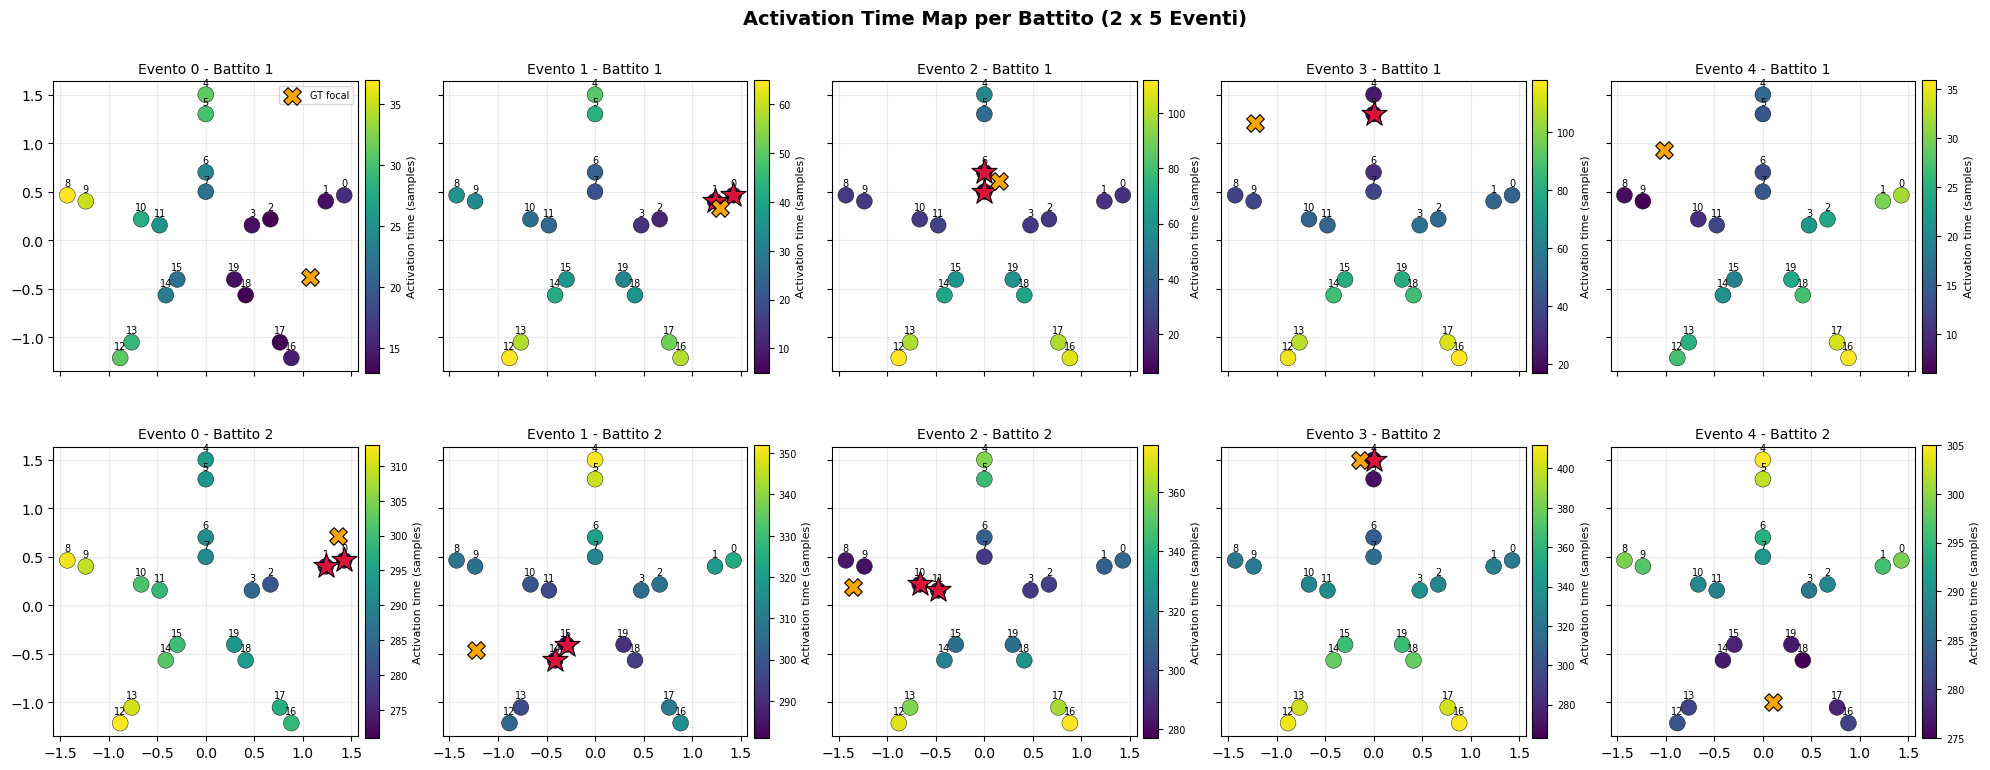

In [53]:
sensor_locs = np.load('checkpoint1sensorlocations.npy')
gt_focal = np.load('checkpoint1FocalPoints.npy')

n_events = 5 
sensor_locs = sensor_locs - 2

fig, axes = plt.subplots(2, n_events, figsize=(4 * n_events, 8), sharex=True, sharey=True)

# Gestione del caso limite di un solo evento per non rompere l'indicizzazione di axes
if n_events == 1:
    axes = np.array(axes).reshape(2, 1)

for ev in range(n_events):
    sig_ev = signals_filtered[ev, :, :]
 
    timings, LS = GroupSolutionCP1(sig_ev)
    
    # Conversione in array NumPy per estrarre le colonne (i battiti) facilmente
    timings_arr = np.array(timings, dtype=float)
    ls_arr = np.array(LS, dtype=float)

    for beat_idx in range(2):
        ax = axes[beat_idx, ev]
        
        # Estrazione dei dati per il battito corrente [tutti i sensori, colonna del battito]
        first_act = timings_arr[:, beat_idx]
        wave_ls = ls_arr[:, beat_idx]

        valid = np.isfinite(first_act)
        
        if np.any(valid):
            vmin = np.nanmin(first_act[valid])
            vmax = np.nanmax(first_act[valid])
            sc = ax.scatter(
                sensor_locs[valid, 0], sensor_locs[valid, 1],
                c=first_act[valid], cmap='viridis', vmin=vmin, vmax=vmax,
                s=130, edgecolors='k', linewidths=0.3, zorder=2
            )
            cbar = fig.colorbar(sc, ax=ax, fraction=0.045, pad=0.02)
            cbar.set_label('Activation time (samples)', fontsize=8)
            cbar.ax.tick_params(labelsize=7)
        else:
            # Fallback se un battito non ha attivazioni valide
            ax.scatter(sensor_locs[:, 0], sensor_locs[:, 1],
                       c='lightgray', s=130, edgecolors='k', linewidths=0.3, zorder=1)

        # Etichette sensori
        for i, (x, y) in enumerate(sensor_locs):
            ax.annotate(str(i), (x, y), fontsize=7, ha='center', va='bottom',
                        xytext=(0, 5), textcoords='offset points')

        # Overlay sensori focali predetti per quel battito (dove LS > 0)
        pred_idx = np.where(wave_ls > 0)[0]
        if len(pred_idx) > 0:
            ax.scatter(sensor_locs[pred_idx, 0], sensor_locs[pred_idx, 1],
                       marker='*', s=360, c='crimson', edgecolors='black',
                       linewidths=0.8, zorder=4, label='Pred focal')

        # GT focal del battito corrispondente, con controlli sui limiti degli array
        if ev < gt_focal.shape[0] and beat_idx < gt_focal.shape[1]:
            gp = gt_focal[ev, beat_idx]
            ax.scatter(gp[0], gp[1], marker='X', s=160, c='orange',
                       edgecolors='black', linewidths=0.8, zorder=5, label='GT focal')

        ax.set_title(f'Evento {ev} - Battito {beat_idx + 1}', fontsize=10)
        ax.set_aspect('equal')
        ax.grid(True, alpha=0.25)
        
        # Mostra la legenda 
        if ev == 0 and beat_idx == 0:
            ax.legend(fontsize=7, loc='best')

plt.suptitle('Activation Time Map per Battito (2 x 5 Eventi)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()